# Dermoscopy Copilot — 05. Human-in-the-Loop: Simulated Dermatologists and Annotation Quality

**Course:** Human-Centered Artificial Intelligence (HCAI) · MSc in Biomedical Engineering · University of Coimbra
· **Group 13:** Carolina Garrido, Sara Santos, Sara Seco

## Purpose of this notebook

In the notebook 04_active_learning.ipynb, the oracle used in the active learning loop is replaced with a more realistic simulation of human annotation. Previously, the oracle was either perfect or introduced random errors, without accounting for differences in diagnostic difficulty between skin lesion classes.Instead, this notebook simulates a panel of five dermatologists, each with distinct diagnostic accuracy and class-specific confusion patterns. This allows the simulation to capture more realistic annotation errors, such as melanomas being more likely to be misclassified as nevi than as vascular lesions.

The main objectives are to:

- **Simulated panel:** Each dermatologist has their own accuracy and a confusion matrix with **structured errors** (for example `mel ↔ nv`, `bkl ↔ mel`, `akiec ↔ bcc/bkl`), defined in `annotators.py`.
- **Oracles:** `perfect` (always the correct label), `single` (each image is labelled by one dermatologist chosen at random) and `majority` (each image is labelled by 3 different dermatologists and the majority vote wins).
- **Annotation cost:** The human cost is the number of **annotations**, not the number of images. An image seen by 3 dermatologists costs 3.
- **Annotation quality:** Accuracy of each dermatologist against the ground truth, agreement between annotators and Krippendorff's alpha, with the same formulas as the course spreadsheet *"Human-in-the-Loop Machine Learning: annotation quality frameworks"*.
- **Experiment:** The best query strategy of notebook 04 (hybrid) and random sampling are run with each oracle and 10 seeds, from 10% to about 52% of the training images labelled, and compared with paired statistical tests.
- **Who decides at inference:** The final active learning model is exported for the app, and a referral rule decides which cases are sent to the clinician (*human in the loop*) and which are only supervised (*human on the loop*).

The experiments were run with the scripts in the root of the repository (`al_hitl.py`, `hitl_extra_stats.py`, `export_al_head.py` and `referral.py`), and their results are saved in `results/`.

This notebook requires the `features/features_<BACKBONE>/` folder produced by notebook `02_feature_extraction.ipynb`, the active learning results of notebook `04_active_learning.ipynb` in `results/tables/`, and the results of the scripts above in `results/tables/`, `results/figures/`, `results/heads/` and `results/results_active_learning/`.

## 1. Library imports

In [1]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch                        # saves the linear heads of each cycle
from IPython.display import Image as IPImage, display   # shows the saved figures
from scipy.stats import wilcoxon    # paired, non-parametric statistical test

# Base path, one level up if the notebook is inside the 'notebooks' folder
BASE_DIR = Path("..") if Path.cwd().name == "notebooks" else Path(".")
# The scripts of the project use paths relative to the root of the repository,
# so the notebook works from the root and imports the modules from there
os.chdir(BASE_DIR.resolve())
sys.path.insert(0, str(Path.cwd()))

# Active learning loop of notebook 04 (same model, query strategies and data)
from active_learning import (STRATEGIES, ActiveLearner, LinearHead, MAX_FRAC, initial_split,
                             load_data, test_metrics)
# Simulated dermatologists and annotation quality metrics
from annotators import (CLASSES, MISSING, PANEL_ACCURACY, PANEL_NAMES, Oracle, annotator_confusion,
                        error_structure, quality_report, selftest)

## 2. Configuration

The experiment uses the three oracles of the saved results (`ORACLES`), the same 10 `SEEDS` as notebook 04 and `K` = 3 dermatologists per image in the `majority` oracle. The linear head of every cycle is saved for the first `HEAD_SEEDS` seeds, because notebook `06_gradcam.ipynb` uses them to study the heat maps at different labelling budgets.

`annotators.py` also has a fourth oracle, `uniform`, which makes random errors in 10% of the images. It is not used here because it is the same experiment as the noisy oracle of notebook 04.

In [2]:
TABLES = Path("results") / "tables"
FIGURES = Path("results") / "figures"
HEADS = Path("results") / "heads"                           # linear heads saved at every cycle
AL_DIR = Path("results") / "results_active_learning"        # final active learning model (used by the app)

ORACLES = ["perfect", "single", "majority"]   # oracles of the saved results
SEEDS = list(range(10))   # same 10 seeds as in notebook 04
HEAD_SEEDS = 3            # seeds whose linear heads are saved (used by notebook 06)
K = 3                     # dermatologists per image in the 'majority' oracle

# Saved results of the Human-in-the-Loop experiments
saved = ["hitl_runs.csv", "hitl_annotator_quality.csv", "hitl_summary.csv", "hitl_quality_summary.csv",
         "hitl_disagreement.csv", "hitl_stats.csv", "hitl_majority_vs_single.csv", "referral_results.csv"]
for f in saved:
    print(f"{f:30s}", "found" if (TABLES / f).exists() else "MISSING")
print(f"{'heads in results/heads/':30s}", len(list(HEADS.glob("*.pt"))), "files")
print(f"{'al_head.pt':30s}", "found" if (AL_DIR / "al_head.pt").exists() else "MISSING")

hitl_runs.csv                  found
hitl_annotator_quality.csv     found
hitl_summary.csv               found
hitl_quality_summary.csv       found
hitl_disagreement.csv          found
hitl_stats.csv                 found
hitl_majority_vs_single.csv    found
referral_results.csv           found
heads in results/heads/        18 files
al_head.pt                     found


## 3. Simulated panel of dermatologists

The panel has five dermatologists with different overall accuracies (`PANEL_ACCURACY`). These values are **illustrative**: they are not taken from the literature and are a modelling assumption of the project.

When a dermatologist makes a mistake, the wrong class is not chosen at random. The **error structure** gives, for each true class (rows), how the errors are spread over the other classes (columns). It is inspired by the confusions of the model in notebook 03 (`mel ↔ nv`, `bkl ↔ mel`, `akiec ↔ bcc/bkl`) and by common dermoscopic confusions. Each row adds up to 1 and the diagonal is 0.

In [3]:
# Overall accuracy of each simulated dermatologist
display(pd.DataFrame({"accuracy": PANEL_ACCURACY}, index=PANEL_NAMES).T)

# Error structure: for each true class (rows), share of the errors given to each wrong class (columns)
pd.DataFrame(error_structure(), index=CLASSES, columns=CLASSES).round(2)

,Derm 1,Derm 2,Derm 3,Derm 4,Derm 5
accuracy,0.92,0.88,0.85,0.8,0.75


,akiec,bcc,bkl,df,mel,nv,vasc
akiec,0.00,0.40,0.40,0.00,0.20,0.00,0.0
bcc,0.50,0.00,0.25,0.00,0.25,0.00,0.0
bkl,0.17,0.17,0.00,0.00,0.33,0.33,0.0
df,0.00,0.00,0.29,0.00,0.14,0.57,0.0
mel,0.09,0.00,0.36,0.00,0.00,0.55,0.0
nv,0.00,0.00,0.36,0.09,0.55,0.00,0.0
vasc,0.00,0.40,0.00,0.20,0.00,0.40,0.0


The confusion matrix of each dermatologist combines both: the diagonal is their accuracy and the remaining probability is spread according to the error structure. The figure shows the most and the least accurate dermatologists of the panel.

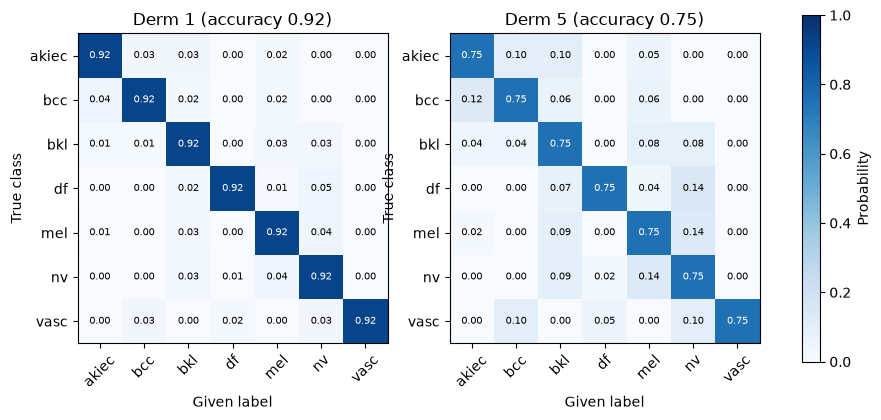

In [4]:
# Confusion matrix P(given label | true class) of the best and of the worst dermatologist
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, i in zip(axes, [0, len(PANEL_ACCURACY) - 1]):
    C = annotator_confusion(PANEL_ACCURACY[i])
    im = ax.imshow(C, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(7)); ax.set_xticklabels(CLASSES, rotation=45)
    ax.set_yticks(range(7)); ax.set_yticklabels(CLASSES)
    for r in range(7):
        for c in range(7):
            ax.text(c, r, f"{C[r, c]:.2f}", ha="center", va="center", fontsize=7,
                    color="white" if C[r, c] > 0.5 else "black")
    ax.set_xlabel("Given label")
    ax.set_ylabel("True class")
    ax.set_title(f"{PANEL_NAMES[i]} (accuracy {PANEL_ACCURACY[i]:.2f})")
fig.colorbar(im, ax=axes, label="Probability")
plt.show()

## 4. Oracles and annotation cost

The oracle answers the requests of the active learning loop. For each requested image it returns the final label, the votes of the dermatologists and the number of annotations used:

- **`perfect`:** the correct label, without any dermatologist (the oracle of notebook 04).
- **`single`:** one dermatologist of the panel, chosen at random for each image. It costs 1 annotation per image.
- **`majority`:** 3 different dermatologists, chosen at random for each image, and the majority vote wins (ties are broken at random). It costs 3 annotations per image.

To see what each oracle gives, 1000 images of the training pool are labelled by each of them. The `uniform` oracle is included only for comparison.

In [5]:
d = load_data()   # same data as notebook 04: features of the three splits and labels of the training pool
print("Training pool:", len(d["y_orig"]), "images | validation:", len(d["yva"]), "| test:", len(d["yte"]))

# Small demonstration: 1000 images of the training pool are labelled by each oracle
demo = np.random.default_rng(0).choice(len(d["y_orig"]), 1000, replace=False)
y_demo = d["y_orig"][demo]
rows = []
for kind in ["perfect", "uniform", "single", "majority"]:
    labels, votes, cost = Oracle(kind, np.random.default_rng(0), k=K).annotate(y_demo)
    rows.append(dict(oracle=kind, label_accuracy=(labels == y_demo).mean(), annotations=cost,
                     annotations_per_image=cost / len(y_demo)))
pd.DataFrame(rows).set_index("oracle").round(3)

Training pool: 7153 images | validation: 1431 | test: 1431


,label_accuracy,annotations,annotations_per_image
oracle,,,
perfect,1.000,1000,1.0
uniform,0.911,1000,1.0
single,0.849,1000,1.0
majority,0.943,3000,3.0


## 5. Annotation quality metrics

The quality of the collected annotations is measured with the metrics of the course spreadsheet:

- **Accuracy against the ground truth:** fraction of the annotations of each dermatologist that match the true diagnosis.
- **Agreement between annotators:** for each dermatologist, how often they agree with the other dermatologists who labelled the same image.
- **Krippendorff's alpha:** agreement between annotators corrected for the agreement expected by chance (1 = perfect agreement, 0 = chance level). Only images with at least 2 annotations are used, so it only exists for the `majority` oracle.

Before using these metrics, `selftest` checks them against the example of the spreadsheet (5 annotators, 11 tasks and 4 labels). The values must match the spreadsheet.

In [6]:
selftest()

alpha = 0.803103   (sheet: 0.803103)
p_a   = 0.857266   (sheet: 0.857266)   p_e = 0.275087   (sheet: 0.275087)
accuracy vs GT: [0.714286 0.9      1.       1.       0.75    ]   (sheet: 0.714286 0.9 1 1 0.75)
agreement (self-excluded): [0.785714 0.944444 0.845238 0.845238 0.791667]
OK: matches the spreadsheet.


## 6. Active learning with simulated dermatologists

The function `run_hitl` is the active learning run of notebook 04 (`run_experiment`) with the oracle replaced by the simulated panel. For one query strategy, one oracle and one seed:

- **Cycle 0:** the initial 10% of the training images are also labelled by the oracle, and the model is trained with early stopping on the validation macro F1-score.
- **Cycles:** the query strategy selects 300 images, the oracle labels them and the model is retrained for 3 epochs, until about 52% of the training images are labelled.
- **Recorded per cycle:** the validation macro F1-score, the number of labelled images, the number of annotations (human cost), the accuracy of the collected labels and, for the `majority` oracle, the fraction of queried images on which the dermatologists disagree.
- **At the end:** the test metrics of the final model and the annotation quality metrics. For the first `HEAD_SEEDS` seeds, the linear head of every cycle and the labelled images of the last cycle are saved.

In [7]:
def run_hitl(strategy, oracle_kind, seed, d, k=3, head_path=None):
    # One complete run: one strategy, one oracle, one seed. Returns (history, quality)
    np.random.seed(seed)                              # random_sampling uses the global np.random
    rng = np.random.default_rng(1000 + seed)
    oracle = Oracle(oracle_kind, rng, k=k)
    y_true = d["y_orig"]
    n_img = len(y_true)

    labelled = initial_split(y_true, seed)
    y_given = y_true.copy()                           # final label given by the "panel" to each image
    votes_all = np.full((n_img, oracle.P), MISSING, dtype=int)
    cost = {"n": 0}                                   # number of annotations requested so far (human cost)

    def ask(idx):
        # Asks the annotators to label the images idx (indices of original images)
        y, votes, c = oracle.annotate(y_true[idx])
        y_given[idx], votes_all[idx] = y, votes
        cost["n"] += c
        return votes

    def labelled_data():                              # the 3 versions of every labelled image
        rows = np.isin(d["idtr"], d["ids_orig"][labelled])
        return d["Xtr"][rows], y_given[d["row_to_img"][rows]]

    ask(np.where(labelled)[0])                        # the initial labels also come from the annotators
    X_l, y_l = labelled_data()
    model = LinearHead(seed=seed).fit(X_l, y_l, epochs=100, X_val=d["Xva"], y_val=d["yva"])
    learner = ActiveLearner(model, STRATEGIES[strategy])

    heads = {}

    def snapshot():
        # Saves a copy of the linear head, indexed by the number of labelled images
        heads[int(labelled.sum())] = {n: p.clone() for n, p in model.net.state_dict().items()}

    def record(cycle, chosen=None, votes=None):
        # One row of the history: validation F1, cost and label quality at this cycle
        row = dict(strategy=strategy, oracle=oracle_kind, seed=seed, cycle=cycle,
                   n_labelled=int(labelled.sum()), n_annotations=cost["n"],
                   val_f1=learner.score(d["Xva"], d["yva"]),
                   label_acc=float((y_given[labelled] == y_true[labelled]).mean()),
                   disagree_rate=np.nan, requested_classes=None)
        if chosen is not None:
            row["requested_classes"] = np.bincount(y_true[chosen], minlength=7).tolist()
            if oracle_kind == "majority":             # % of queried images on which the doctors disagree
                row["disagree_rate"] = float(np.mean(
                    [len(set(r[r != MISSING])) > 1 for r in votes]))
        return row

    hist = [record(0)]
    snapshot()
    cycle = 0
    while labelled.sum() < MAX_FRAC * n_img:
        cycle += 1
        pool = np.where(~labelled)[0]
        chosen = pool[learner.query(d["Xtr"][d["orig"][pool]])]
        labelled[chosen] = True
        votes = ask(chosen)
        X_l, y_l = labelled_data()
        learner.teach(X_l, y_l, epochs=3)
        hist.append(record(cycle, chosen, votes))
        snapshot()
    hist[-1].update(test_metrics(learner, d))

    quality = dict(strategy=strategy, oracle=oracle_kind, seed=seed)
    quality.update(quality_report(votes_all[labelled], y_true[labelled], y_given[labelled]))
    quality["n_annotations"] = cost["n"]              # real cost (perfect/uniform do not record votes)
    if head_path is not None:
        os.makedirs(os.path.dirname(head_path), exist_ok=True)
        torch.save(heads, head_path)
        # Also saves the labelled images of the last cycle and the labels given by the annotators
        # (used to retrain the model with the corrections of the clinician, notebook 07)
        np.savez(head_path.replace(".pt", "_labelled.npz"), image_ids=d["ids_orig"][labelled], labels=y_given[labelled])
    return hist, quality

The query strategy compared with random sampling is the best one of notebook 04, chosen on the validation set only (highest mean macro F1-score over the cycles). Two strategies, three oracles and 10 seeds correspond to 60 runs and take a long time, so by default the saved results of `al_hitl.py` are loaded. Setting `RETRAIN = True` runs all the experiments again and replaces the saved tables and heads.

In [8]:
RETRAIN = False   # True runs the 60 experiments again, False loads the saved results

# Best strategy, chosen on the validation set only (as in notebook 04)
curves = pd.read_csv(TABLES / "al_curves.csv")
best = curves[curves.strategy != "random"].groupby("strategy").val_f1.mean().idxmax()
print("AL strategy:", best)

if RETRAIN:
    rows, qual = [], []
    for strategy in (best, "random"):
        for oracle in ORACLES:
            for seed in SEEDS:
                print(f"running {strategy} | {oracle} | seed {seed}", flush=True)
                hp = str(HEADS / f"{strategy}__{oracle}__seed{seed}.pt") if seed < HEAD_SEEDS else None
                h, q = run_hitl(strategy, oracle, seed, d, k=K, head_path=hp)
                rows += h
                qual.append(q)
    res = pd.DataFrame(rows)
    res.to_csv(TABLES / "hitl_runs.csv", index=False)
    quality = pd.DataFrame(qual)
    quality.to_csv(TABLES / "hitl_annotator_quality.csv", index=False)
else:
    res = pd.read_csv(TABLES / "hitl_runs.csv")
    quality = pd.read_csv(TABLES / "hitl_annotator_quality.csv")

print("Rows:", len(res), "| strategies:", sorted(res.strategy.unique()), "| oracles:", sorted(res.oracle.unique()),
      "| seeds:", res.seed.nunique(), "| cycles:", res.cycle.max())

AL strategy: hybrid
Rows: 660 | strategies: ['hybrid', 'random'] | oracles: ['majority', 'perfect', 'single'] | seeds: 10 | cycles: 10


## 7. Results at the last cycle

At the last cycle all runs have the same number of labelled images (3715, about 52% of the training set), but not the same cost: the `majority` oracle used three times more annotations. The table shows, for each strategy and oracle, the mean over the 10 seeds of the cost, of the accuracy of the collected labels (`label_acc`) and of the test metrics of the final model.

In [9]:
# Summary at the last cycle (mean and standard deviation over the seeds)
final = res[res.cycle == res.cycle.max()]
summ = final.groupby(["strategy", "oracle"]).agg(
    n_labelled=("n_labelled", "mean"), n_annotations=("n_annotations", "mean"),
    label_acc=("label_acc", "mean"),
    test_f1=("test_f1", "mean"), test_f1_std=("test_f1", "std"),
    test_bal_acc=("test_bal_acc", "mean"), test_recall_mel=("test_recall_mel", "mean"),
    test_recall_mel_std=("test_recall_mel", "std")).round(4)

saved_summ = pd.read_csv(TABLES / "hitl_summary.csv", index_col=[0, 1])
print("Same as the saved table:", np.allclose(summ.values, saved_summ.values))
summ

Same as the saved table: True


n_labelled  n_annotations  label_acc  test_f1  test_f1_std  \
strategy oracle                                                                 
hybrid   majority      3715.0        11145.0     0.9472   0.5825       0.0091   
         perfect       3715.0         3715.0     1.0000   0.6082       0.0109   
         single        3715.0         3715.0     0.8395   0.5216       0.0147   
random   majority      3715.0        11145.0     0.9454   0.5332       0.0125   
         perfect       3715.0         3715.0     1.0000   0.5742       0.0152   
         single        3715.0         3715.0     0.8389   0.4740       0.0174   

                   test_bal_acc  test_recall_mel  test_recall_mel_std  
strategy oracle                                                        
hybrid   majority        0.6160           0.5491               0.0226  
         perfect         0.6144           0.5686               0.0374  
         single          0.5767           0.5421               0.0472  
random   majority        0.5913           0.6050               0.0697  
         perfect         0.5930           0.5811               0.0439  
         single          0.5455           0.5358               0.0481

With a single dermatologist per image, only about 84% of the collected labels are correct, and the test macro F1-score of the hybrid strategy drops from 0.608 (perfect oracle) to 0.522. The majority vote of 3 dermatologists raises the label accuracy to about 95% and recovers most of this loss (0.583), at three times the annotation cost. In all three settings the hybrid strategy stays above random sampling.

## 8. Annotation quality

The quality metrics of section 5 are computed on all the labelled images of each run and averaged over the seeds. For the `perfect` oracle there are no votes, so only the final label accuracy is defined. Krippendorff's alpha only exists for the `majority` oracle, because it is the only one with more than one annotation per image.

In [10]:
# Quality of the collected annotations (mean over seeds)
qsum = quality.groupby(["strategy", "oracle"]).mean(numeric_only=True).drop(columns="seed").round(4)

saved_qsum = pd.read_csv(TABLES / "hitl_quality_summary.csv", index_col=[0, 1])
print("Same as the saved table:", np.allclose(qsum.values, saved_qsum.values, equal_nan=True))
qsum

Same as the saved table: True


krippendorff_alpha  observed_agreement  expected_agreement  \
strategy oracle                                                                 
hybrid   majority              0.5830              0.7171              0.3214   
         perfect                  NaN                 NaN                 NaN   
         single                   NaN                 NaN                 NaN   
random   majority              0.5369              0.7155              0.3857   
         perfect                  NaN                 NaN                 NaN   
         single                   NaN                 NaN                 NaN   

                   n_annotations  acc_Derm 1  acc_Derm 2  acc_Derm 3  \
strategy oracle                                                        
hybrid   majority        11145.0      0.9213      0.8804      0.8519   
         perfect          3715.0         NaN         NaN         NaN   
         single           3715.0      0.9206      0.8774      0.8495   
random   majority        11145.0      0.9198      0.8811      0.8508   
         perfect          3715.0         NaN         NaN         NaN   
         single           3715.0      0.9191      0.8755      0.8492   

                   acc_Derm 4  acc_Derm 5  label_accuracy_final  
strategy oracle                                                  
hybrid   majority      0.8038      0.7512                0.9472  
         perfect          NaN         NaN                1.0000  
         single        0.7927      0.7601                0.8395  
random   majority      0.8002      0.7506                0.9454  
         perfect          NaN         NaN                1.0000  
         single        0.7950      0.7582                0.8389

The accuracy of each dermatologist on the collected labels matches the values of the panel (0.92 to 0.75), which confirms that the oracle behaves as intended. Krippendorff's alpha is moderate (about 0.54–0.58): the dermatologists agree well above chance, but far from perfectly.

The next table shows the fraction of the images queried in each cycle on which the 3 dermatologists of the `majority` oracle did not all agree.

In [11]:
# Disagreement between doctors on the queried images (majority oracle, cycles after the initial set)
dis = (res[(res.oracle == "majority") & (res.cycle > 0)]
       .groupby("strategy").disagree_rate.agg(["mean", "std"]).round(4))
saved_dis = pd.read_csv(TABLES / "hitl_disagreement.csv", index_col=0)
print("Same as the saved table:", np.allclose(dis.values, saved_dis.values))
dis

Same as the saved table: True


,mean,std
strategy,,
hybrid,0.4042,0.0265
random,0.4075,0.0283


The dermatologists disagree on about 40% of the queried images, and this rate is almost the same for the hybrid strategy and for random sampling. This result must be read with care: the simulated dermatologists make mistakes based on the **class** of the image, not on how difficult the image is. The disagreement rate therefore only reflects the mix of classes that was queried, and it cannot show whether active learning picks the images that are harder for a human.

## 9. Statistical tests

As in notebook 04, the runs are compared seed by seed, because for the same seed they start from the same initial labelled set and the same model (paired design). We use the two-sided Wilcoxon signed-rank test and the Holm correction over all the comparisons of the table. Two families of comparisons are made:

- **AL vs random:** for each oracle, the hybrid strategy against random sampling, using the test macro F1-score at the last cycle and the mean validation macro F1-score over the cycles.
- **Oracle vs perfect:** for the hybrid strategy, the test macro F1-score of each imperfect oracle against the perfect oracle, which measures the cost of imperfect labels.

In [12]:
def holm(p):
    # Holm correction for multiple comparisons; returns the adjusted p-values in the original order
    p = np.asarray(p, dtype=float)
    order = np.argsort(p)
    adj, running = np.empty(len(p)), 0.0
    for rank, i in enumerate(order):
        running = max(running, (len(p) - rank) * p[i])
        adj[i] = min(1.0, running)
    return adj


def safe_wilcoxon(a, b):
    # Wilcoxon signed-rank p-value, or NaN when the test cannot be run
    try:
        return wilcoxon(a, b).pvalue
    except ValueError:                                # all the differences are zero
        return np.nan

In [13]:
# Paired tests (same seed = same initial set) with the Holm correction
pf = final.pivot_table(index="seed", columns=["strategy", "oracle"], values="test_f1")
mean_val = (res[res.cycle > 0].groupby(["strategy", "oracle", "seed"]).val_f1.mean()
            .unstack(["strategy", "oracle"]))
tests = []
for oracle in ORACLES:                                # AL vs random, for each oracle
    for name, tab in (("test F1 (last cycle)", pf), ("mean val F1 (cycles)", mean_val)):
        a, b = tab[(best, oracle)], tab[("random", oracle)]
        tests.append(dict(family="AL vs random", summary=name, oracle=oracle,
                          comparison=f"{best} vs random", mean_diff=(a - b).mean(),
                          seeds_better=int(((a - b) > 0).sum()), n_seeds=len(a),
                          p=safe_wilcoxon(a, b)))
for oracle in [o for o in ORACLES if o != "perfect"]:   # cost of the label quality: each oracle vs perfect
    a, b = pf[(best, oracle)], pf[(best, "perfect")]
    tests.append(dict(family="oracle vs perfect", summary="test F1 (last cycle)",
                      oracle=oracle, comparison=f"{oracle} vs perfect ({best})",
                      mean_diff=(a - b).mean(), seeds_better=int(((a - b) > 0).sum()),
                      n_seeds=len(a), p=safe_wilcoxon(a, b)))
stats = pd.DataFrame(tests)
stats["p_holm"] = holm(stats.p.fillna(1.0))
stats = stats.round(4)

saved_stats = pd.read_csv(TABLES / "hitl_stats.csv")
print("Same as the saved table:", np.allclose(stats.select_dtypes("number"), saved_stats.select_dtypes("number")))
stats

Same as the saved table: True


,family,summary,oracle,comparison,mean_diff,seeds_better,n_seeds,p,p_holm
0,AL vs random,test F1 (last cycle),perfect,hybrid vs random,0.0340,10,10,0.0020,0.0156
1,AL vs random,mean val F1 (cycles),perfect,hybrid vs random,0.0259,9,10,0.0039,0.0156
2,AL vs random,test F1 (last cycle),single,hybrid vs random,0.0476,10,10,0.0020,0.0156
3,AL vs random,mean val F1 (cycles),single,hybrid vs random,0.0568,10,10,0.0020,0.0156
4,AL vs random,test F1 (last cycle),majority,hybrid vs random,0.0493,10,10,0.0020,0.0156
5,AL vs random,mean val F1 (cycles),majority,hybrid vs random,0.0423,10,10,0.0020,0.0156
6,oracle vs perfect,test F1 (last cycle),single,single vs perfect (hybrid),-0.0866,0,10,0.0020,0.0156
7,oracle vs perfect,test F1 (last cycle),majority,majority vs perfect (hybrid),-0.0257,0,10,0.0020,0.0156


The hybrid strategy is better than random sampling with every oracle, in all 10 seeds for the test macro F1-score (corrected p = 0.016 in all cases). Active learning therefore keeps its advantage when the labels come from imperfect dermatologists, and the gain is even slightly larger with imperfect oracles (about +0.05) than with the perfect one (+0.03). Both imperfect oracles are worse than the perfect one in all seeds: about −0.087 with one dermatologist and −0.026 with the majority vote.

## 10. Majority vote or a single dermatologist?

The majority vote gives better labels, but each image costs 3 annotations. `hitl_extra_stats.py` compares both oracles in two ways, for each strategy:

1. **Same images:** test macro F1-score at the last cycle. Both oracles have the same labelled images, but the majority vote costs 3 times more.
2. **Same human cost:** validation macro F1-score at the same number of annotations. The learning curves only have one point per cycle, so they are linearly interpolated (per seed) and compared at 3 costs inside the range covered by both oracles. Validation is used because the test F1-score is only computed at the last cycle.

The difference is `majority − single`, so positive values favour the majority vote.

In [14]:
def make_row(strategy, basis, a, b):
    # One row of the table: means, paired differences (majority - single) and the Wilcoxon p-value
    diff = a.values - b.values
    return dict(strategy=strategy, basis=basis, mean_majority=a.mean(), mean_single=b.mean(),
                mean_diff=diff.mean(), std_diff=diff.std(ddof=1),
                seeds_majority_better=int((diff > 0).sum()), n_seeds=len(diff),
                p=safe_wilcoxon(a.values, b.values))


rows = []
for strategy in sorted(res.strategy.unique()):
    g = res[res.strategy == strategy]
    maj, sin = g[g.oracle == "majority"], g[g.oracle == "single"]
    seeds = sorted(set(maj.seed) & set(sin.seed))

    # 1) same images, test F1 at the last cycle
    def last(df):
        # Test F1 at the last cycle, one value per seed
        d_ = df[df.cycle == df.cycle.max()].set_index("seed")
        return d_.test_f1.loc[seeds]
    rows.append(make_row(strategy, "test F1, same images (last cycle)", last(maj), last(sin)))

    # 2) same human cost, validation F1 interpolated per seed
    def curve(df, s):
        # Learning curve of one seed: number of annotations (x) and validation F1 (y)
        d_ = df[df.seed == s].sort_values("n_annotations")
        return d_.n_annotations.values.astype(float), d_.val_f1.values
    # Range of annotation costs covered by both oracles
    lo = max(maj.n_annotations.min(), sin.n_annotations.min())
    hi = min(maj.n_annotations.max(), sin.n_annotations.max())
    if lo >= hi:
        print(f"[{strategy}] the curves do not overlap in cost; no comparison at equal cost.")
        continue
    for c in np.linspace(lo, hi, 3):
        a = pd.Series({s: np.interp(c, *curve(maj, s)) for s in seeds})
        b = pd.Series({s: np.interp(c, *curve(sin, s)) for s in seeds})
        rows.append(make_row(strategy, f"val F1, same cost ({c:.0f} annotations)", a, b))

mvs = pd.DataFrame(rows)
mvs["p_holm"] = holm(mvs.p.fillna(1.0))
mvs = mvs.round(4)

saved_mvs = pd.read_csv(TABLES / "hitl_majority_vs_single.csv")
print("Same as the saved table:", np.allclose(mvs.select_dtypes("number"), saved_mvs.select_dtypes("number")))
mvs

Same as the saved table: True


,strategy,basis,mean_majority,mean_single,mean_diff,std_diff,seeds_majority_better,n_seeds,p,p_holm
0,hybrid,"test F1, same images (last cycle)",0.5825,0.5216,0.0609,0.0161,10,10,0.0020,0.0156
1,hybrid,"val F1, same cost (2145 annotations)",0.5604,0.5708,-0.0104,0.0235,4,10,0.2754,0.5508
2,hybrid,"val F1, same cost (2930 annotations)",0.5647,0.5866,-0.0219,0.0288,1,10,0.0488,0.1953
3,hybrid,"val F1, same cost (3715 annotations)",0.5826,0.5758,0.0069,0.0175,6,10,0.3223,0.5508
4,random,"test F1, same images (last cycle)",0.5332,0.4740,0.0592,0.0226,10,10,0.0020,0.0156
5,random,"val F1, same cost (2145 annotations)",0.5604,0.4992,0.0612,0.0145,10,10,0.0020,0.0156
6,random,"val F1, same cost (2930 annotations)",0.5405,0.5178,0.0227,0.0280,8,10,0.0371,0.1855
7,random,"val F1, same cost (3715 annotations)",0.5424,0.5258,0.0166,0.0220,8,10,0.0488,0.1953


With the **same images**, the majority vote is clearly better (about +0.06 in the test macro F1-score, in all 10 seeds). With the **same human cost**, the picture changes: for the hybrid strategy the differences are small and none is significant after the Holm correction, so spending the annotations on more images labelled once is about as useful as spending them on fewer images labelled three times. For random sampling the majority vote is better at the lowest cost (2145 annotations), but the advantage becomes small and not significant at higher costs.

## 11. Learning curves

The figure shows the validation macro F1-score of each strategy and oracle, with the mean and standard deviation over the 10 seeds. On the left, against the number of labelled images; on the right, against the number of annotations requested from the dermatologists (human cost). Solid lines are the hybrid strategy and dashed lines are random sampling.

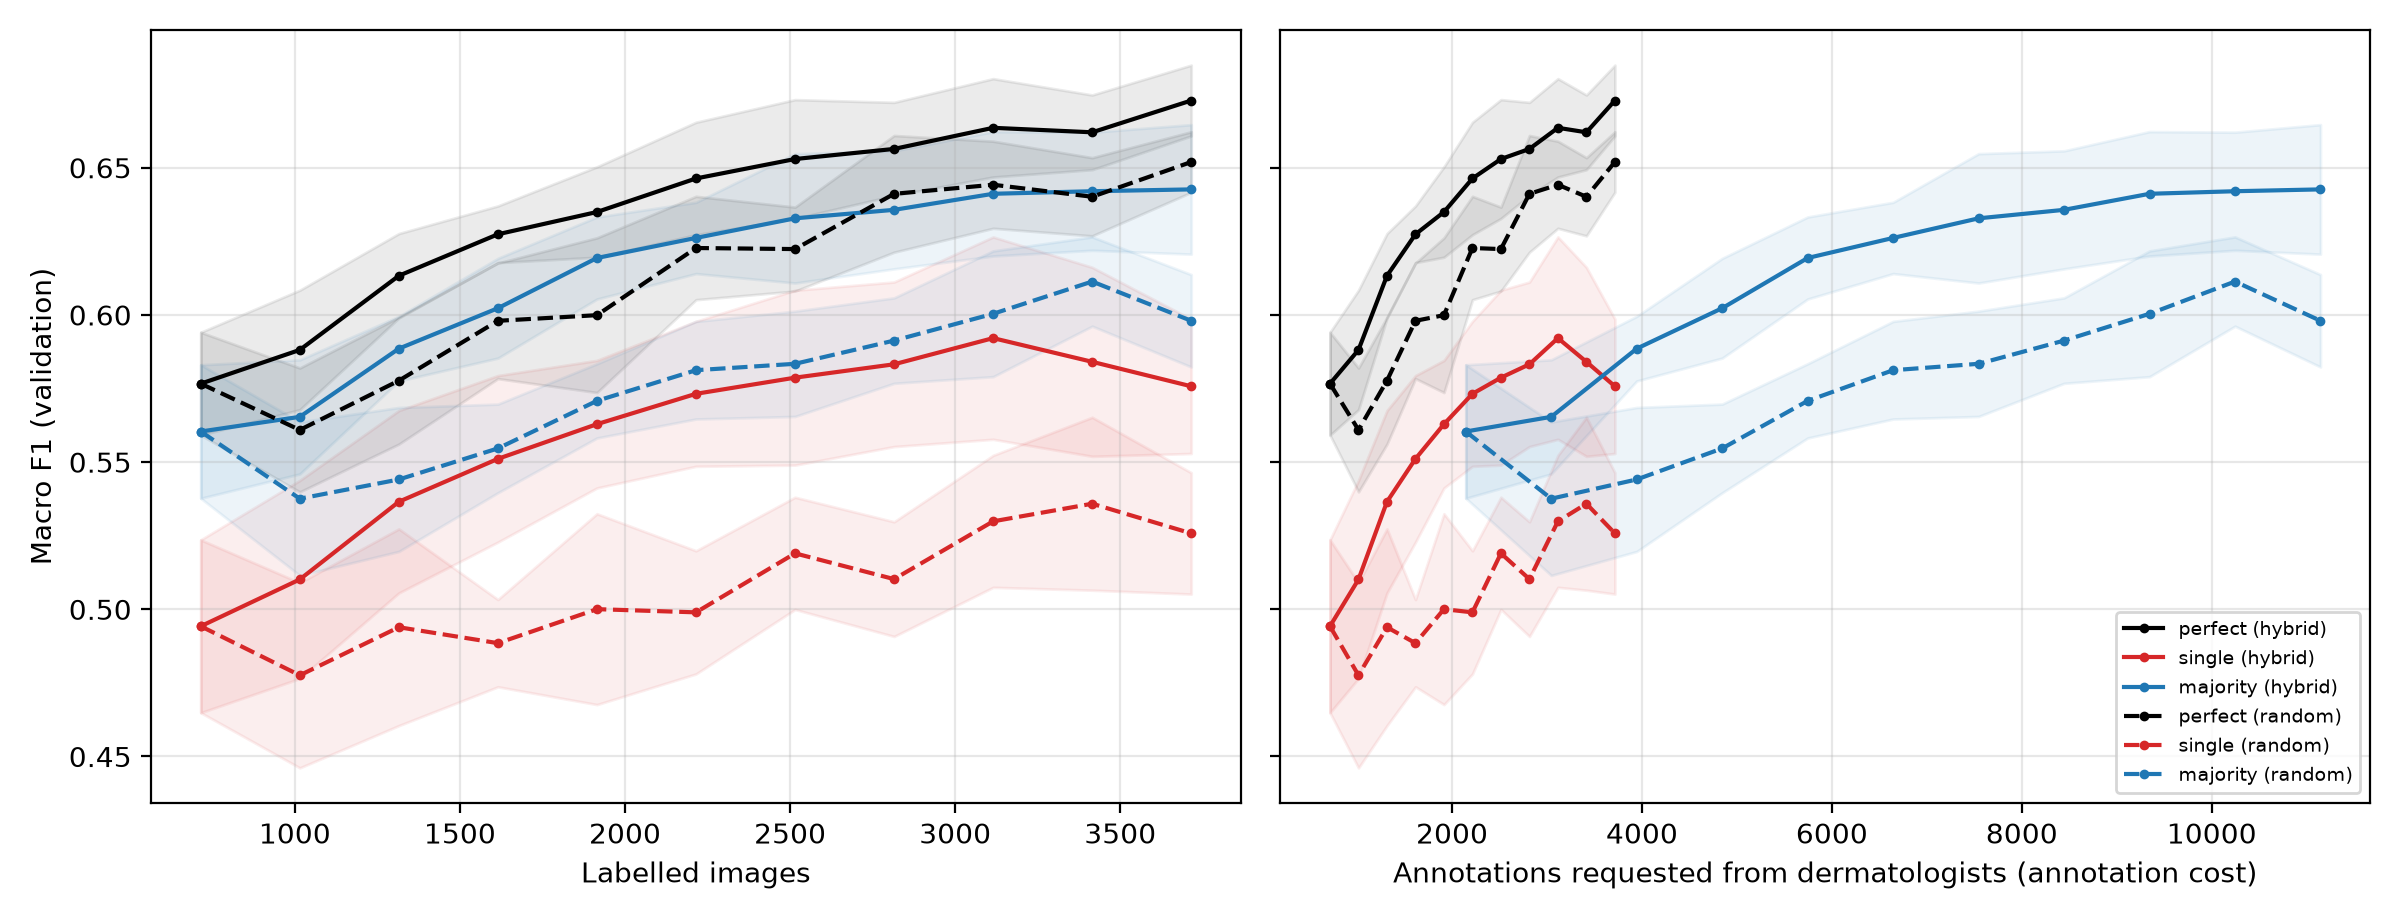

In [15]:
# Validation learning curves: against labelled images (left) and against annotations (right)
display(IPImage(filename=str(FIGURES / "hitl_curves.png"), width=900))

## 12. Final active learning model for the app

The app of notebook `07_copilot_app.ipynb` uses one final active learning model. `export_al_head.py` takes the linear head saved at the last cycle of the run **hybrid, perfect oracle, seed 0** (3715 labelled images), calibrates it on the validation set with temperature scaling, evaluates it on the test set and saves it as `al_head.pt`, in the same format as the baseline of notebook 03. It also saves the labelled images of this run (`al_labelled.npz`), which are used to retrain the model with the corrections of the clinician.

In [16]:
# Test metrics of the final active learning model (saved by export_al_head.py)
with open(AL_DIR / "al_head_metrics.json", encoding="utf-8") as f:
    al_m = json.load(f)
pd.Series(al_m).to_frame("final active learning model")

,final active learning model
strategy,hybrid
oracle,perfect
seed,0
n_labelled,3715
f1_macro,0.593178
balanced_acc,0.598782
recall_melanoma,0.591195
auc_macro,0.926009
temperature,0.991949
backbone,tf_efficientnetv2_s.in21k_ft_in1k


## 13. Who decides: the referral rule

At inference, the human is also in the loop: the model should not decide alone on the cases where it is uncertain or where a melanoma is possible. `referral.py` evaluates the rule used by the app, with the probabilities of the final active learning model calibrated on the validation set:

- **Sent to the human (*human in the loop*):** the confidence of the model is below a threshold `X`, **or** the probability of melanoma is at least 20%.
- **Kept by the model (*human on the loop*):** all the other cases, shown as a suggestion under the supervision of the clinician.

The second condition reflects the clinical cost of a missed melanoma. For each threshold `X`, the table gives the percentage of cases sent to the human (human workload), the errors of the model on the cases it keeps and the melanomas missed by the model.

In [17]:
referral = pd.read_csv(TABLES / "referral_results.csv")
cols = ["split", "conf_threshold_X", "pct_sent_human", "ai_errors", "ai_error_rate_total_pct",
        "missed_melanomas", "total_melanomas", "missed_mel_pct"]
referral[cols]

,split,conf_threshold_X,pct_sent_human,ai_errors,ai_error_rate_total_pct,missed_melanomas,total_melanomas,missed_mel_pct
0,val,0.50,29.07,119,8.32,44,159,27.67
1,val,0.60,32.91,95,6.64,39,159,24.53
2,val,0.70,36.69,76,5.31,33,159,20.75
3,val,0.80,44.93,50,3.49,17,159,10.69
4,val,0.90,58.77,17,1.19,7,159,4.40
5,val,0.95,71.56,7,0.49,4,159,2.52
6,test,0.50,31.38,108,7.55,34,159,21.38
7,test,0.60,35.08,88,6.15,30,159,18.87
8,test,0.70,39.20,62,4.33,26,159,16.35
9,test,0.80,45.84,40,2.80,15,159,9.43


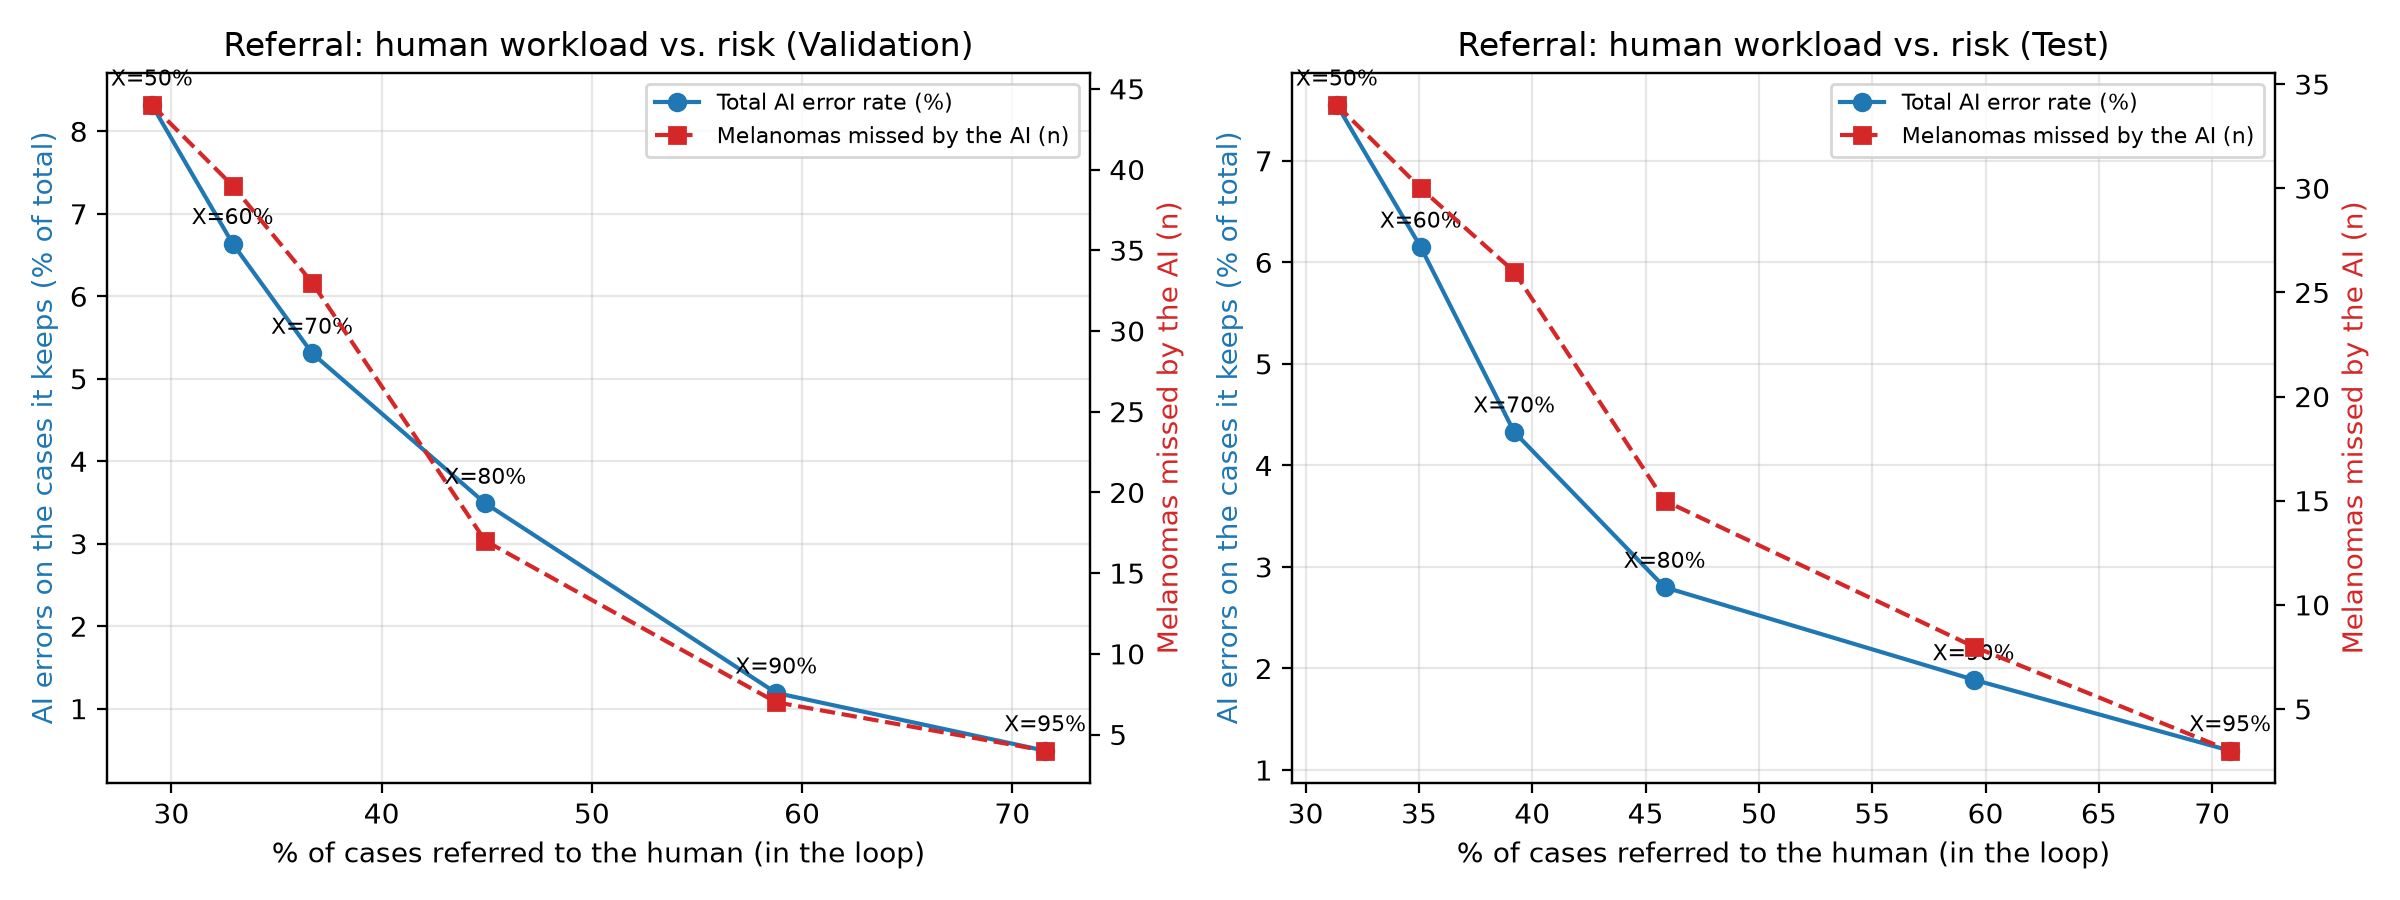

In [18]:
# Trade-off between the human workload and the risk of the cases kept by the model
display(IPImage(filename=str(FIGURES / "referral_tradeoff.png"), width=900))

Raising `X` sends more cases to the clinician and reduces both the errors and the missed melanomas of the model. The app uses `X = 0.80`: on the test set, 45.8% of the cases are sent to the clinician, the errors of the model on the cases it keeps correspond to 2.8% of all cases, and 15 of the 159 melanomas (9.4%) are missed by the model. Higher thresholds miss fewer melanomas, but send most of the cases to the clinician (about 60% with `X = 0.90`).

## 14. Saved results

The results of the Human-in-the-Loop experiments are saved in the `results` folder:

- `tables/hitl_runs.csv`: validation macro F1-score, cost and label accuracy after every cycle, and test metrics at the last cycle, for every strategy, oracle and seed.
- `tables/hitl_annotator_quality.csv` and `tables/hitl_quality_summary.csv`: annotation quality metrics per run and averaged over the seeds.
- `tables/hitl_summary.csv`: results at the last cycle.
- `tables/hitl_disagreement.csv`: disagreement between dermatologists on the queried images.
- `tables/hitl_stats.csv` and `tables/hitl_majority_vs_single.csv`: paired statistical tests.
- `tables/referral_results.csv` and `figures/referral_tradeoff.png`: evaluation of the referral rule.
- `figures/hitl_curves.png`: learning curves of section 11.
- `heads/`: linear heads of every cycle for the first 3 seeds (used by notebook `06_gradcam.ipynb`).
- `results_active_learning/`: final active learning model used by the app (`al_head.pt`, `al_head_metrics.json` and `al_labelled.npz`).